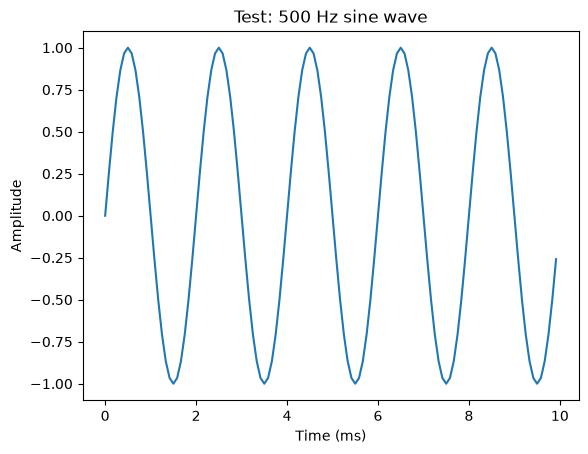

In [9]:
import numpy as np
import matplotlib.pyplot as plt

fs = 12000                      # sampling rate: 12,000 samples per second
t = np.arange(0, 0.01, 1 / fs)  # 10 ms of time
x = np.sin(2 * np.pi * 500 * t) # a 500 Hz sine wave

plt.plot(t * 1000, x)
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Test: 500 Hz sine wave")
plt.show()

In [1]:
from scipy.io import loadmat
data = loadmat("../data/raw/97.mat")
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])


In [2]:
signal = data["X097_DE_time"]
print(signal.shape)

(243938, 1)


In [3]:
print(signal.shape[0] / 12000)


20.328166666666668


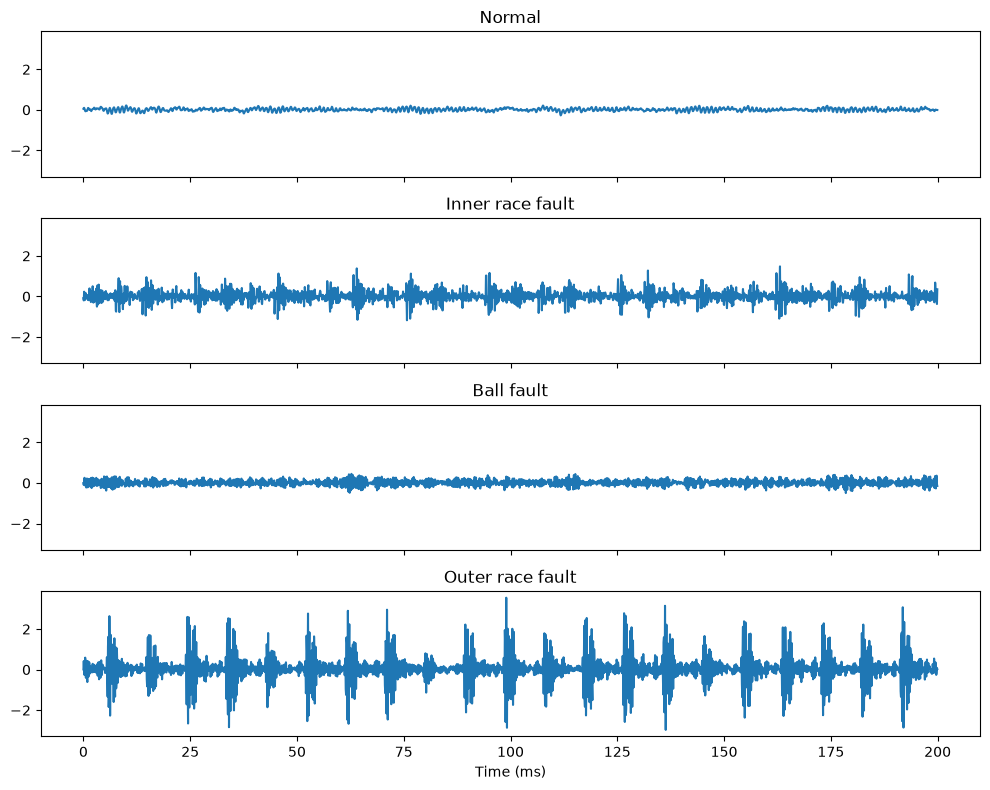

In [4]:
from scipy.io import loadmat
import matplotlib.pyplot as plt
import numpy as np

files = {"Normal": "97", "Inner race fault": "105", "Ball fault": "118", "Outer race fault": "130"}

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)
t = np.arange(2400) / 12000 * 1000  # first 0.2 s, in milliseconds

for ax, (label, num) in zip(axes, files.items()):
    data = loadmat(f"../data/raw/{num}.mat")
    key = [k for k in data if k.endswith("DE_time")][0]  # e.g. "X105_DE_time"
    signal = data[key].ravel()
    ax.plot(t, signal[:2400])
    ax.set_title(label)

axes[-1].set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

In [5]:
import numpy as np

def make_windows(signal, window_size, step):
    windows = []
    for start in range(0, len(signal) - window_size + 1, step):
        windows.append(signal[start: start
                               + window_size
                              ])
    return np.array(windows)

# Test with the toy example
print(make_windows(np.arange(10), window_size=4, step=2))

[[0 1 2 3]
 [2 3 4 5]
 [4 5 6 7]
 [6 7 8 9]]


In [6]:
data = loadmat("../data/raw/97.mat")
signal = data["X097_DE_time"].ravel()

windows = make_windows(signal, window_size=2048, step=2048)
print(windows.shape)

(119, 2048)


In [7]:
split = int(len(signal) * 0.8)   # index where the last 20% starts

train_part = signal[:split]
test_part  = signal[split:]    

train_windows = make_windows(train_part, window_size=2048, step=2048)
test_windows  = make_windows(test_part,  window_size=2048, step=2048)

print("train:", train_windows.shape)
print("test: ", test_windows.shape)

train: (95, 2048)
test:  (23, 2048)


In [8]:
files = {"97": 0, "105": 1, "118": 2, "130": 3}   # file number -> class label

X_train, y_train, X_test, y_test = [], [], [], []

for num, label in files.items():
    data = loadmat(f"../data/raw/{num}.mat")
    key = [k for k in data if k.endswith("DE_time")][0]
    signal = data[key].ravel()

    # 1) split FIRST (no leakage)
    split = int(len(signal) * 0.8)
    train_part = signal[:split]
    test_part  = signal[split:]

    # 2) THEN window each part separately
    tr = make_windows(train_part, window_size=2048, step=2048)
    te = make_windows(test_part,  window_size=2048, step=2048)

    # 3) store windows + a label for each window
    X_train.append(tr); y_train.append(np.full(len(tr), label))
    X_test.append(te);  y_test.append(np.full(len(te), label))

# glue the 4 lists into single arrays
X_train = np.concatenate(X_train); y_train = np.concatenate(y_train)
X_test  = np.concatenate(X_test);  y_test  = np.concatenate(y_test)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)
print("Windows per class (train):", np.bincount(y_train))

X_train: (236, 2048) y_train: (236,)
X_test:  (56, 2048) y_test:  (56,)
Windows per class (train): [95 47 47 47]


In [10]:
from scipy.stats import kurtosis

def rms(x):
    return np.sqrt(np.mean(x ** 2))

class_names = ["Normal", "Inner race", "Ball", "Outer race"]

for label, name in enumerate(class_names):
    w = X_train[y_train == label]                 # all train windows of this class
    r = np.mean([rms(x) for x in w])              # average RMS
    k = np.mean([kurtosis(x) for x in w])         # average kurtosis
    print(f"{name:12s}  RMS = {r:.3f}   kurtosis = {k:.2f}")

Normal        RMS = 0.074   kurtosis = -0.24
Inner race    RMS = 0.291   kurtosis = 2.36
Ball          RMS = 0.138   kurtosis = -0.06
Outer race    RMS = 0.672   kurtosis = 4.60


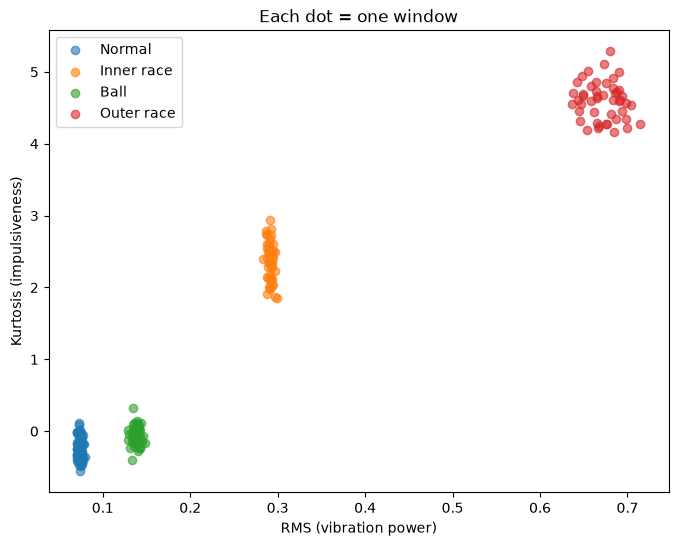

In [11]:
plt.figure(figsize=(8, 6))
for label, name in enumerate(class_names):
    w = X_train[y_train == label]
    r = [rms(x) for x in w]
    k = [kurtosis(x) for x in w]
    plt.scatter(r, k, label=name, alpha=0.6)

plt.xlabel("RMS (vibration power)")
plt.ylabel("Kurtosis (impulsiveness)")
plt.title("Each dot = one window")
plt.legend()
plt.show()

In [12]:
def extract_features(windows):
    feats = []
    for w in windows:
        r = rms(w)
        peak = np.max(np.abs(w))
        feats.append([r, kurtosis(w), peak, peak / r])
    return np.array(feats)

feature_names = ["rms", "kurtosis", "peak", "crest_factor"]

F_train = extract_features(X_train)
F_test  = extract_features(X_test)
print(F_train.shape, F_test.shape)

(236, 4) (56, 4)


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(F_train, y_train)          # learn the boundaries from train windows
pred = rf.predict(F_test)         # predict test windows it has never seen

print(classification_report(y_test, pred, target_names=class_names))

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        23
  Inner race       1.00      1.00      1.00        11
        Ball       1.00      1.00      1.00        11
  Outer race       1.00      1.00      1.00        11

    accuracy                           1.00        56
   macro avg       1.00      1.00      1.00        56
weighted avg       1.00      1.00      1.00        56



In [14]:
# load -> {file number: class label}
FILES = {
    0: {"97": 0, "105": 1, "118": 2, "130": 3},
    1: {"98": 0, "106": 1, "119": 2, "131": 3},
    2: {"99": 0, "107": 1, "120": 2, "132": 3},
    3: {"100": 0, "108": 1, "121": 2, "133": 3},
}

def load_windows(file_map, window_size=2048):
    X, y = [], []
    for num, label in file_map.items():
        data = loadmat(f"../data/raw/{num}.mat")
        signal = data[f"X{num.zfill(3)}_DE_time"].ravel()   # e.g. "X097_DE_time"
        w = make_windows(signal, window_size, window_size)
        X.append(w); y.append(np.full(len(w), label))
    return np.concatenate(X), np.concatenate(y)

# Train on 0 hp only
X_tr, y_tr = load_windows(FILES[0])
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(extract_features(X_tr), y_tr)

# Test on each unseen load
for load in [1, 2, 3]:
    X_te, y_te = load_windows(FILES[load])
    pred = rf.predict(extract_features(X_te))
    acc = (pred == y_te).mean()
    print(f"Train 0 hp -> Test {load} hp: accuracy = {acc:.3f}")

Train 0 hp -> Test 1 hp: accuracy = 1.000
Train 0 hp -> Test 2 hp: accuracy = 1.000
Train 0 hp -> Test 3 hp: accuracy = 1.000


In [15]:
from sklearn.metrics import confusion_matrix
from bearing_fault_detection.cwru import CATALOG, CLASS_NAMES, DATA_DIR

def load_signal(num):
    data = loadmat(DATA_DIR / f"{num}.mat")
    key = f"X{num:03d}_DE_time"
    if key not in data:  # a few CWRU files use a different variable name
        key = [k for k in data if k.endswith("DE_time")][0]
    return data[key].ravel()

def win(sig):
    return make_windows(sig, 2048, 2048)

TEST_SIZE = 0.014
X_tr, y_tr, X_te, y_te = [], [], [], []

for num, (label, size, load) in CATALOG.items():
    sig = load_signal(num)
    if label == 0:                        # Normal: only one healthy bearing -> time split
        split = int(len(sig) * 0.8)
        parts = [(sig[:split], X_tr, y_tr), (sig[split:], X_te, y_te)]
    elif size == TEST_SIZE:               # unseen fault bearings -> test
        parts = [(sig, X_te, y_te)]
    else:                                 # other fault sizes -> train
        parts = [(sig, X_tr, y_tr)]
    for s, X, y in parts:
        w = win(s)
        X.append(w); y.append(np.full(len(w), label))

X_tr, y_tr = np.concatenate(X_tr), np.concatenate(y_tr)
X_te, y_te = np.concatenate(X_te), np.concatenate(y_te)
print("train windows per class:", np.bincount(y_tr))
print("test windows per class: ", np.bincount(y_te))

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(extract_features(X_tr), y_tr)
pred = rf.predict(extract_features(X_te))

print(classification_report(y_te, pred, target_names=CLASS_NAMES))
print(confusion_matrix(y_te, pred))

train windows per class: [662 473 472 472]
test windows per class:  [164 236 236 236]
              precision    recall  f1-score   support

      Normal       0.83      1.00      0.91       164
  Inner race       0.00      0.00      0.00       236
        Ball       0.33      0.93      0.48       236
  Outer race       0.00      0.00      0.00       236

    accuracy                           0.44       872
   macro avg       0.29      0.48      0.35       872
weighted avg       0.24      0.44      0.30       872

[[164   0   0   0]
 [  0   0 236   0]
 [ 16   0 220   0]
 [ 17   0 219   0]]


/Users/batu/projects/bearing-fault-detection/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/batu/projects/bearing-fault-detection/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/batu/projects/bearing-fault-detection/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

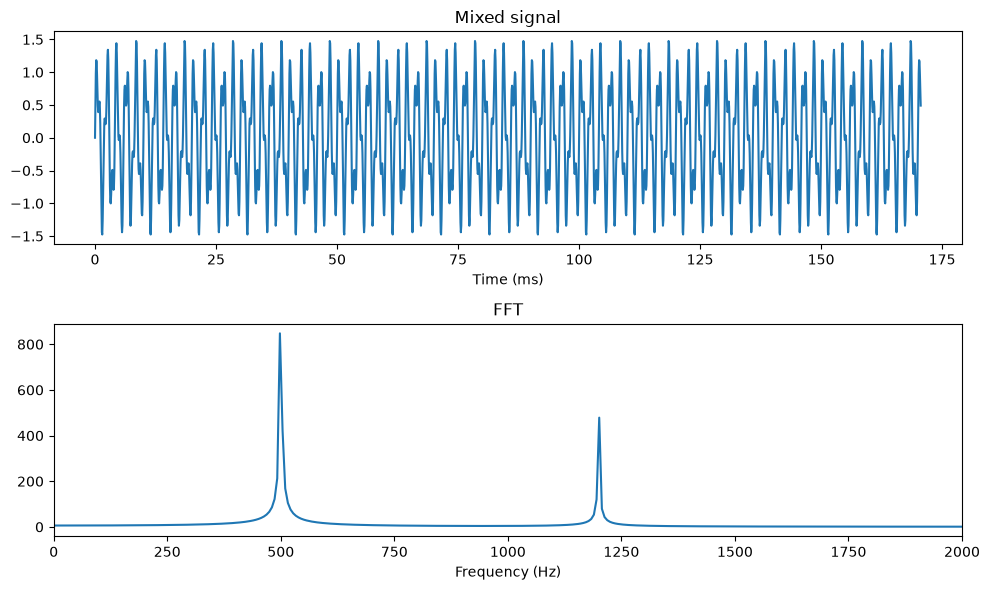

In [16]:
fs = 12000
t = np.arange(2048) / fs
mix = np.sin(2 * np.pi * 500 * t) + 0.5 * np.sin(2 * np.pi * 1200 * t)   # 500 Hz + weaker 1200 Hz

spectrum = np.abs(np.fft.rfft(mix))          # strength of each frequency
freqs = np.fft.rfftfreq(len(mix), d=1 / fs)  # which frequency each value belongs to

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
axes[0].plot(t * 1000, mix); axes[0].set_xlabel("Time (ms)"); axes[0].set_title("Mixed signal")
axes[1].plot(freqs, spectrum); axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_title("FFT")
axes[1].set_xlim(0, 2000)
plt.tight_layout(); plt.show()

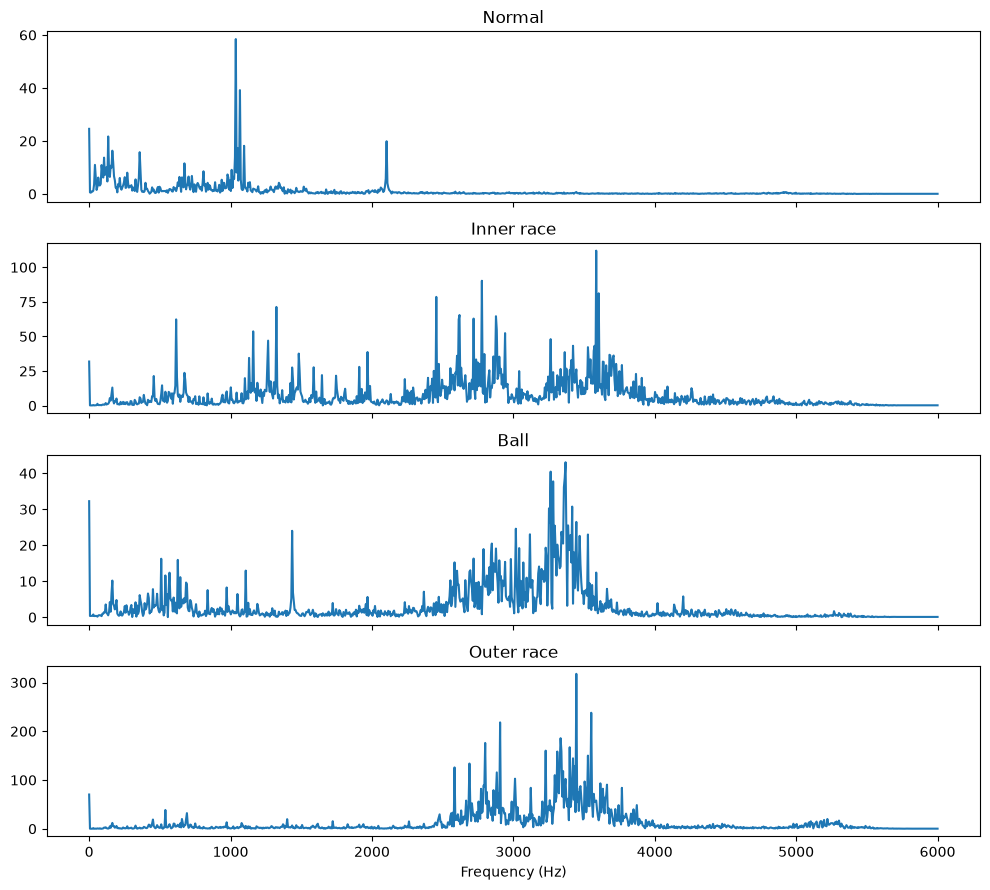

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, (num, name) in zip(axes, [(97, "Normal"), (105, "Inner race"), (118, "Ball"), (130, "Outer race")]):
    w = load_signal(num)[:2048]
    ax.plot(np.fft.rfftfreq(2048, 1 / fs), np.abs(np.fft.rfft(w)))
    ax.set_title(name)
axes[-1].set_xlabel("Frequency (Hz)")
plt.tight_layout(); plt.show()

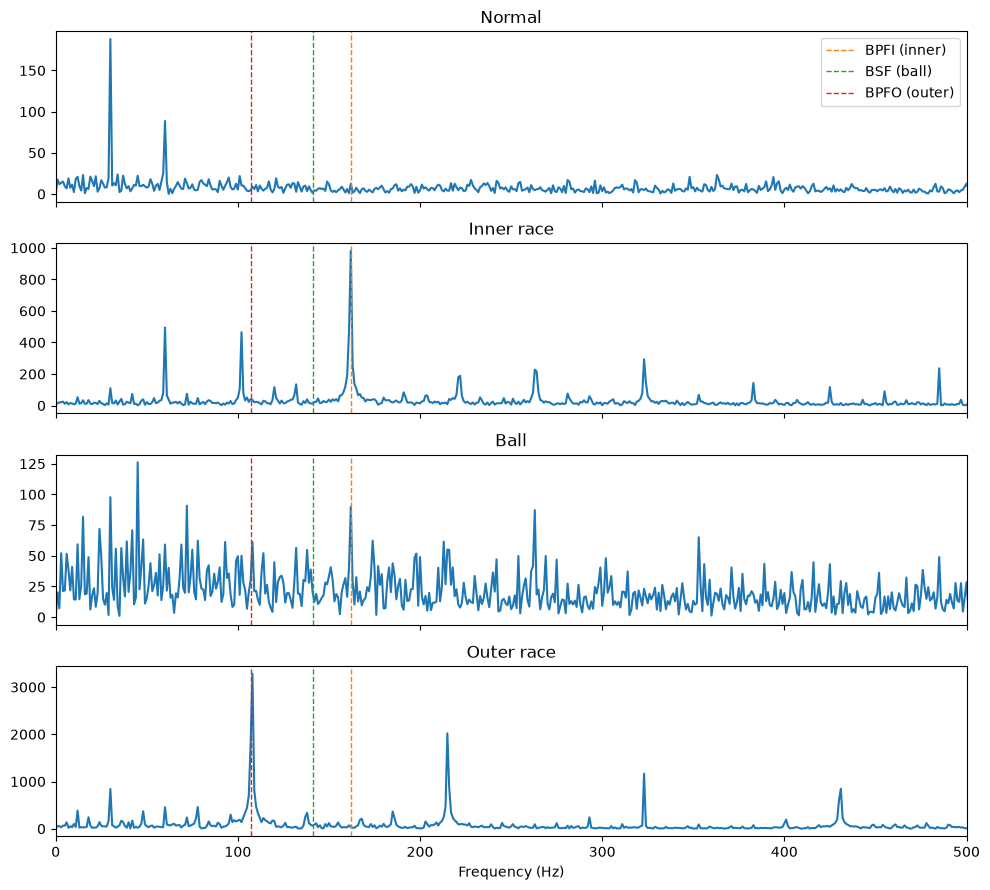

In [18]:
from scipy.signal import hilbert

# Expected fault frequencies for this bearing (SKF 6205) at 1797 rpm
fr = 1797 / 60                      # shaft rotation: ~30 Hz
expected = {"BPFI (inner)": 5.4152 * fr, "BSF (ball)": 4.7135 * fr, "BPFO (outer)": 3.5848 * fr}

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, (num, name) in zip(axes, [(97, "Normal"), (105, "Inner race"), (118, "Ball"), (130, "Outer race")]):
    x = load_signal(num)[:12000]                 # 1 second -> 1 Hz resolution
    env = np.abs(hilbert(x - x.mean()))          # envelope = "rhythm" of the impacts
    env -= env.mean()
    ax.plot(np.fft.rfftfreq(len(env), 1 / fs), np.abs(np.fft.rfft(env)))
    for (lbl, f), c in zip(expected.items(), ["tab:orange", "tab:green", "tab:red"]):
        ax.axvline(f, color=c, ls="--", lw=1, label=lbl)
    ax.set_title(name)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, 500)
plt.tight_layout(); plt.show()

In [19]:
from sklearn.metrics import f1_score

RPM = {0: 1797, 1: 1772, 2: 1750, 3: 1730}
ORDERS = {"bpfi": 5.4152, "bsf": 4.7135, "bpfo": 3.5848}   # fault frequency / shaft frequency

def envelope_features(window, rpm, fs=12000):
    env = np.abs(hilbert(window - window.mean()))
    env -= env.mean()
    spec = np.abs(np.fft.rfft(env))
    freqs = np.fft.rfftfreq(len(env), 1 / fs)
    ref = np.median(spec) + 1e-12            # overall level -> makes features amplitude-independent
    feats = []
    for order in ORDERS.values():
        for h in (1, 2):                     # fundamental + 2nd harmonic
            f0 = h * order * rpm / 60
            band = (freqs > f0 - 6) & (freqs < f0 + 6)
            feats.append(spec[band].max() / ref)
    return feats

# Rebuild the fault-size split, this time also remembering the rpm of each window
X_tr, y_tr, r_tr, X_te, y_te, r_te = [], [], [], [], [], []
for num, (label, size, load) in CATALOG.items():
    sig, rpm = load_signal(num), RPM[load]
    if label == 0:
        split = int(len(sig) * 0.8)
        parts = [(sig[:split], X_tr, y_tr, r_tr), (sig[split:], X_te, y_te, r_te)]
    elif size == TEST_SIZE:
        parts = [(sig, X_te, y_te, r_te)]
    else:
        parts = [(sig, X_tr, y_tr, r_tr)]
    for s, X, y, r in parts:
        w = win(s)
        X.append(w); y.append(np.full(len(w), label)); r.append(np.full(len(w), rpm))

X_tr, y_tr, r_tr = map(np.concatenate, (X_tr, y_tr, r_tr))
X_te, y_te, r_te = map(np.concatenate, (X_te, y_te, r_te))

E_tr = np.array([envelope_features(w, r) for w, r in zip(X_tr, r_tr)])
E_te = np.array([envelope_features(w, r) for w, r in zip(X_te, r_te)])
T_tr, T_te = extract_features(X_tr), extract_features(X_te)

experiments = {
    "time features (old)": (T_tr, T_te),
    "envelope features":   (E_tr, E_te),
    "time + envelope":     (np.hstack([T_tr, E_tr]), np.hstack([T_te, E_te])),
}
for name, (F_tr, F_te) in experiments.items():
    rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(F_tr, y_tr)
    pred = rf.predict(F_te)
    print(f"\n=== {name} ===  accuracy={np.mean(pred == y_te):.3f}  macro-F1={f1_score(y_te, pred, average='macro'):.3f}")
    print(confusion_matrix(y_te, pred))


=== time features (old) ===  accuracy=0.440  macro-F1=0.348
[[164   0   0   0]
 [  0   0 236   0]
 [ 16   0 220   0]
 [ 17   0 219   0]]

=== envelope features ===  accuracy=0.453  macro-F1=0.412
[[147   0  17   0]
 [  0 131 105   0]
 [118   0 117   1]
 [232   0   4   0]]

=== time + envelope ===  accuracy=0.532  macro-F1=0.485
[[164   0   0   0]
 [  0  79 157   0]
 [ 14   0 221   1]
 [ 20   0 216   0]]


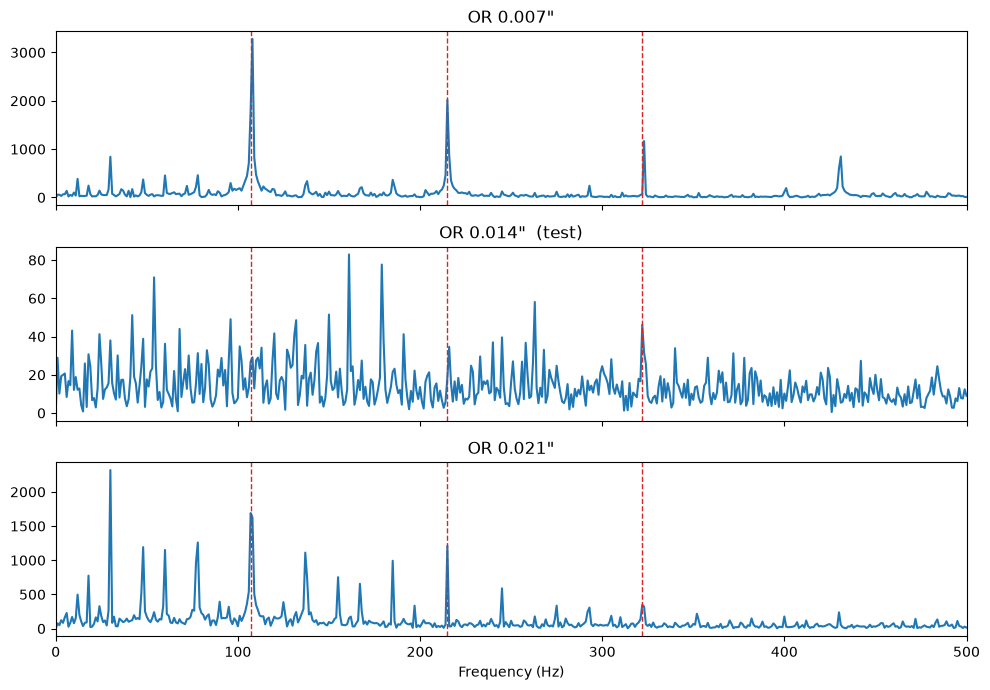

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
bpfo = 3.5848 * 1797 / 60
for ax, (num, name) in zip(axes, [(130, 'OR 0.007"'), (197, 'OR 0.014"  (test)'), (234, 'OR 0.021"')]):
    x = load_signal(num)[:12000]
    env = np.abs(hilbert(x - x.mean())); env -= env.mean()
    ax.plot(np.fft.rfftfreq(len(env), 1 / fs), np.abs(np.fft.rfft(env)))
    for h in (1, 2, 3):
        ax.axvline(h * bpfo, color="tab:red", ls="--", lw=1)
    ax.set_title(name)
axes[-1].set_xlabel("Frequency (Hz)"); axes[-1].set_xlim(0, 500)
plt.tight_layout(); plt.show()

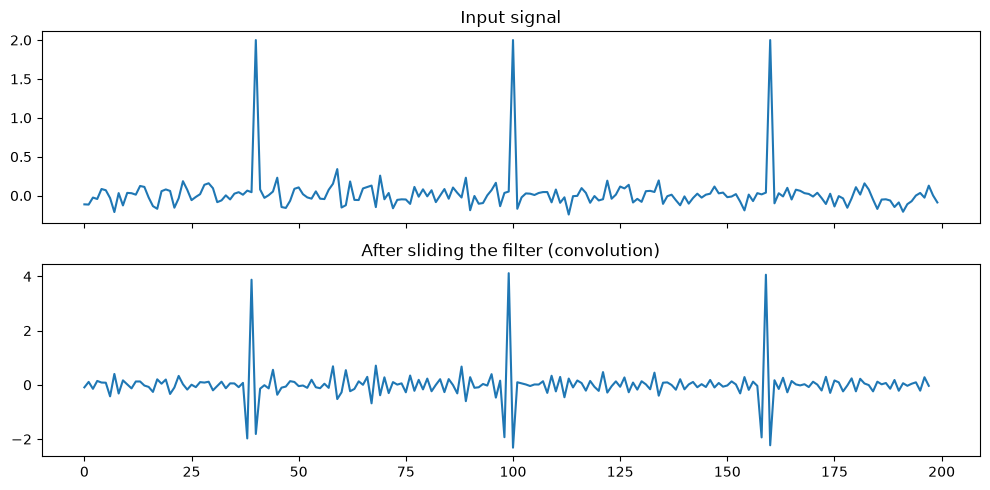

In [21]:
import torch
import torch.nn.functional as F

# A fake signal: small noise + 3 sharp "clicks"
torch.manual_seed(0)
signal = 0.1 * torch.randn(200)
signal[[40, 100, 160]] = 2.0

# A hand-made filter that responds to "a sharp jump up then down"
kernel = torch.tensor([-1.0, 2.0, -1.0])

# conv1d expects shape (batch, channels, length)
out = F.conv1d(signal.view(1, 1, -1), kernel.view(1, 1, -1))

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(signal); axes[0].set_title("Input signal")
axes[1].plot(out.view(-1)); axes[1].set_title("After sliding the filter (convolution)")
plt.tight_layout(); plt.show()

In [22]:
from torch.utils.data import TensorDataset, DataLoader

def to_tensor(X):
    # per-window normalization: remove absolute vibration level, keep the shape/rhythm
    X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 1e-8)
    return torch.tensor(X, dtype=torch.float32).unsqueeze(1)   # (N, 1 channel, 2048)

Xt_tr, Xt_te = to_tensor(X_tr), to_tensor(X_te)
yt_tr, yt_te = torch.tensor(y_tr), torch.tensor(y_te)

train_loader = DataLoader(TensorDataset(Xt_tr, yt_tr), batch_size=64, shuffle=True)
test_loader  = DataLoader(TensorDataset(Xt_te, yt_te), batch_size=256)

print("train:", Xt_tr.shape, " test:", Xt_te.shape)
xb, yb = next(iter(train_loader))
print("one batch:", xb.shape, yb.shape)

train: torch.Size([2079, 1, 2048])  test: torch.Size([872, 1, 2048])
one batch: torch.Size([64, 1, 2048]) torch.Size([64])


In [23]:
import torch.nn as nn

class BearingCNN(nn.Module):
    def __init__(self, n_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            # wide first kernel: catches a whole impact + its ringing, suppresses noise
            nn.Conv1d(1, 16, kernel_size=64, stride=8, padding=28), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=3, padding=1), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=3, padding=1), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 64, kernel_size=3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),   # average over time -> "is the pattern present anywhere?"
        )
        self.classifier = nn.Linear(64, n_classes)

    def forward(self, x):
        x = self.features(x)           # (batch, 64, 1)
        return self.classifier(x.squeeze(-1))   # (batch, 4) scores

model = BearingCNN()
out = model(xb)   # try it on one batch, before any training
print("output shape:", out.shape)
print("number of learnable parameters:", sum(p.numel() for p in model.parameters()))

output shape: torch.Size([64, 4])
number of learnable parameters: 21780


In [24]:
from torch.utils.data import random_split

torch.manual_seed(42)   # reproducible results
full = TensorDataset(Xt_tr, yt_tr)
n_val = int(0.2 * len(full))
train_ds, val_ds = random_split(full, [len(full) - n_val, n_val])
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=256)

model = BearingCNN()
loss_fn = nn.CrossEntropyLoss()                               # "how wrong was the guess?"
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)    # "how to adjust the aim"

def run_epoch(loader, train):
    model.train(train)
    total, correct, loss_sum = 0, 0, 0.0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            out = model(xb)                    # 1. throw (predict)
            loss = loss_fn(out, yb)            # 2. how far off?
            if train:
                optimizer.zero_grad()
                loss.backward()                # 3. which direction to correct?
                optimizer.step()               # 4. adjust the filters
            loss_sum += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            total += len(yb)
    return loss_sum / total, correct / total

history = []
for epoch in range(1, 16):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    history.append((tr_loss, va_loss))
    print(f"epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

epoch  1 | train loss 0.633 acc 0.924 | val loss 0.289 acc 1.000
epoch  2 | train loss 0.125 acc 1.000 | val loss 0.055 acc 1.000
epoch  3 | train loss 0.050 acc 1.000 | val loss 0.028 acc 1.000
epoch  4 | train loss 0.029 acc 1.000 | val loss 0.017 acc 1.000
epoch  5 | train loss 0.019 acc 1.000 | val loss 0.011 acc 1.000
epoch  6 | train loss 0.013 acc 1.000 | val loss 0.009 acc 1.000
epoch  7 | train loss 0.010 acc 1.000 | val loss 0.007 acc 1.000
epoch  8 | train loss 0.010 acc 1.000 | val loss 0.005 acc 1.000
epoch  9 | train loss 0.007 acc 1.000 | val loss 0.004 acc 1.000
epoch 10 | train loss 0.006 acc 1.000 | val loss 0.004 acc 1.000
epoch 11 | train loss 0.005 acc 1.000 | val loss 0.003 acc 1.000
epoch 12 | train loss 0.005 acc 1.000 | val loss 0.002 acc 1.000
epoch 13 | train loss 0.004 acc 1.000 | val loss 0.002 acc 1.000
epoch 14 | train loss 0.003 acc 1.000 | val loss 0.002 acc 1.000
epoch 15 | train loss 0.003 acc 1.000 | val loss 0.002 acc 1.000


In [25]:
model.eval()
with torch.no_grad():                       # no learning here, just predicting
    pred_cnn = torch.cat([model(xb).argmax(1) for xb, _ in test_loader]).numpy()

print(classification_report(y_te, pred_cnn, target_names=CLASS_NAMES, zero_division=0))
print(confusion_matrix(y_te, pred_cnn))
print(f"\nCNN macro-F1: {f1_score(y_te, pred_cnn, average='macro'):.3f}   (RF time+envelope: 0.485)")

# save the trained weights (only the numbers, not code -> safe to load later)
from pathlib import Path
Path("../models").mkdir(exist_ok=True)
torch.save(model.state_dict(), "../models/cnn.pt")

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       164
  Inner race       0.67      0.24      0.36       236
        Ball       0.49      1.00      0.65       236
  Outer race       0.00      0.00      0.00       236

    accuracy                           0.52       872
   macro avg       0.54      0.56      0.50       872
weighted avg       0.50      0.52      0.46       872

[[164   0   0   0]
 [  0  57  41 138]
 [  0   0 236   0]
 [  0  28 208   0]]

CNN macro-F1: 0.502   (RF time+envelope: 0.485)


In [26]:
import pandas as pd
from sklearn.metrics import recall_score

def build_split(test_size):
    """Fault bearings of `test_size` -> test, other sizes -> train. Normal: 80/20 time split."""
    d = {"tr": ([], [], []), "te": ([], [], [])}
    for num, (label, size, load) in CATALOG.items():
        sig, rpm = load_signal(num), RPM[load]
        if label == 0:
            split = int(len(sig) * 0.8)
            parts = [(sig[:split], "tr"), (sig[split:], "te")]
        else:
            parts = [(sig, "te" if size == test_size else "tr")]
        for s, which in parts:
            w = win(s)
            X, y, r = d[which]
            X.append(w); y.append(np.full(len(w), label)); r.append(np.full(len(w), rpm))
    return [np.concatenate(a) for a in (*d["tr"], *d["te"])]

def rf_features(X, r):
    env = np.array([envelope_features(w, rpm) for w, rpm in zip(X, r)])
    return np.hstack([extract_features(X), env])

def train_cnn(X, y, seed, epochs=15):
    torch.manual_seed(seed)
    model = BearingCNN()
    loader = DataLoader(TensorDataset(to_tensor(X), torch.tensor(y)), batch_size=64, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()
    return model

def predict_cnn(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb).argmax(1) for (xb,) in DataLoader(TensorDataset(to_tensor(X)), batch_size=256)]).numpy()

def record(model_name, test_size, seed, y, p):
    rec = recall_score(y, p, labels=[0, 1, 2, 3], average=None, zero_division=0)
    return {"model": model_name, "test_size": test_size, "seed": seed,
            "accuracy": np.mean(p == y), "macro_f1": f1_score(y, p, average="macro"),
            **{f"recall_{n}": v for n, v in zip(["normal", "inner", "ball", "outer"], rec)}}

results = []
for test_size in [0.007, 0.014, 0.021]:
    X_tr, y_tr, r_tr, X_te, y_te, r_te = build_split(test_size)
    F_tr, F_te = rf_features(X_tr, r_tr), rf_features(X_te, r_te)
    for seed in range(5):
        p = RandomForestClassifier(n_estimators=200, random_state=seed).fit(F_tr, y_tr).predict(F_te)
        results.append(record("RF (time+envelope)", test_size, seed, y_te, p))
        p = predict_cnn(train_cnn(X_tr, y_tr, seed), X_te)
        results.append(record("1D-CNN", test_size, seed, y_te, p))
        print(f"test size {test_size} | seed {seed} done")

df = pd.DataFrame(results)
Path("../results").mkdir(exist_ok=True)
df.to_csv("../results/fault_size_cv.csv", index=False)   # small file -> we WILL commit this

print("\n=== macro-F1 per test fault size (mean ± std over 5 seeds) ===")
print(df.groupby(["test_size", "model"])["macro_f1"].agg(["mean", "std"]).round(3))
print("\n=== overall (all 3 folds) ===")
print(df.groupby("model")[["macro_f1", "recall_normal", "recall_inner", "recall_ball", "recall_outer"]].mean().round(3))

test size 0.007 | seed 0 done
test size 0.007 | seed 1 done
test size 0.007 | seed 2 done
test size 0.007 | seed 3 done
test size 0.007 | seed 4 done
test size 0.014 | seed 0 done
test size 0.014 | seed 1 done
test size 0.014 | seed 2 done
test size 0.014 | seed 3 done
test size 0.014 | seed 4 done
test size 0.021 | seed 0 done
test size 0.021 | seed 1 done
test size 0.021 | seed 2 done
test size 0.021 | seed 3 done
test size 0.021 | seed 4 done

=== macro-F1 per test fault size (mean ± std over 5 seeds) ===
                               mean    std
test_size model                           
0.007     1D-CNN              0.736  0.072
          RF (time+envelope)  1.000  0.000
0.014     1D-CNN              0.481  0.046
          RF (time+envelope)  0.492  0.025
0.021     1D-CNN              0.418  0.002
          RF (time+envelope)  0.726  0.052

=== overall (all 3 folds) ===
                    macro_f1  recall_normal  recall_inner  recall_ball  \
model                                

In [27]:
print(df.groupby("model")[["macro_f1", "recall_normal", "recall_inner", "recall_ball", "recall_outer"]].mean().round(3).to_string())

                    macro_f1  recall_normal  recall_inner  recall_ball  recall_outer
model                                                                               
1D-CNN                 0.545            1.0         0.403        0.975         0.052
RF (time+envelope)     0.739            1.0         0.777        0.860         0.451


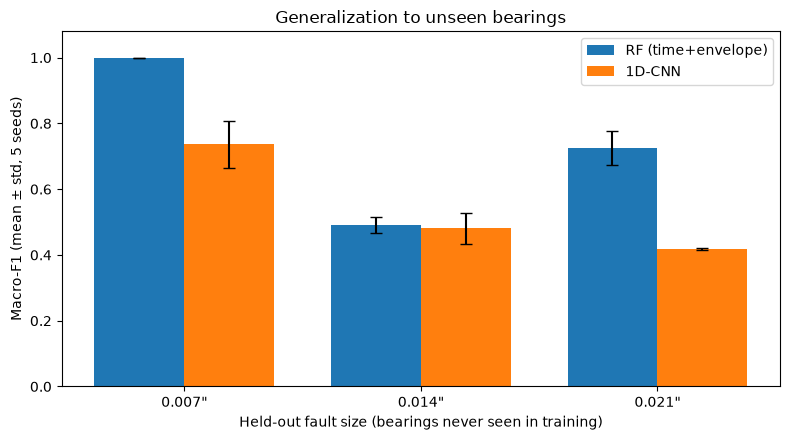

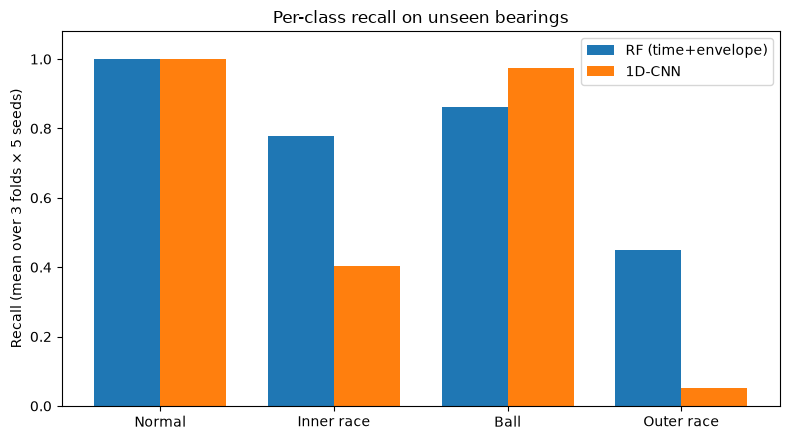

In [28]:
Path("../figures").mkdir(exist_ok=True)
models = ["RF (time+envelope)", "1D-CNN"]

# 1) macro-F1 per held-out fault size
summary = df.groupby(["test_size", "model"])["macro_f1"].agg(["mean", "std"]).unstack("model")
sizes = summary.index
x, w = np.arange(len(sizes)), 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, m in enumerate(models):
    ax.bar(x + (i - 0.5) * w, summary[("mean", m)], w, yerr=summary[("std", m)], capsize=4, label=m)
ax.set_xticks(x); ax.set_xticklabels([f'{s}"' for s in sizes])
ax.set_xlabel("Held-out fault size (bearings never seen in training)")
ax.set_ylabel("Macro-F1 (mean ± std, 5 seeds)")
ax.set_ylim(0, 1.08); ax.legend(); ax.set_title("Generalization to unseen bearings")
plt.tight_layout(); plt.savefig("../figures/macro_f1_by_fold.png", dpi=150); plt.show()

# 2) per-class recall, averaged over all folds and seeds
classes = ["normal", "inner", "ball", "outer"]
rec = df.groupby("model")[[f"recall_{c}" for c in classes]].mean()
x = np.arange(len(classes))
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, m in enumerate(models):
    ax.bar(x + (i - 0.5) * w, rec.loc[m], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel("Recall (mean over 3 folds × 5 seeds)"); ax.set_ylim(0, 1.08)
ax.legend(); ax.set_title("Per-class recall on unseen bearings")
plt.tight_layout(); plt.savefig("../figures/recall_per_class.png", dpi=150); plt.show()

In [31]:
import os, time
import onnxruntime as ort

# 1) Final model: train on ALL bearings (evaluation is done; this is the deployment model)
X_all, y_all = [], []
for num, (label, size, load) in CATALOG.items():
    w = win(load_signal(num))
    X_all.append(w); y_all.append(np.full(len(w), label))
X_all, y_all = np.concatenate(X_all), np.concatenate(y_all)
final = train_cnn(X_all, y_all, seed=0)
final.eval()

# 2) Export to ONNX (batch size can vary)
example = to_tensor(X_all[:1])
torch.onnx.export(final, example, "../models/cnn.onnx",
                  input_names=["signal"], output_names=["logits"],
                  dynamic_axes={"signal": {0: "batch"}, "logits": {0: "batch"}},external_data=False)

# 3) Verify: ONNX must give the same answers as PyTorch
opts = ort.SessionOptions(); opts.intra_op_num_threads = 1      # single thread ~ closer to a small device
sess = ort.InferenceSession("../models/cnn.onnx", opts, providers=["CPUExecutionProvider"])
xb = to_tensor(X_all[:256])
with torch.no_grad():
    ref = final(xb).numpy()
onx = sess.run(None, {"signal": xb.numpy()})[0]
print(f"max abs difference: {np.abs(ref - onx).max():.2e} | same predictions: {(ref.argmax(1) == onx.argmax(1)).all()}")

# 4) Benchmark: one window at a time (like a live sensor)
torch.set_num_threads(1)
x1 = xb[:1]; x1_np = x1.numpy()

def bench(fn, n=500):
    for _ in range(20): fn()                     # warm-up
    t = []
    for _ in range(n):
        s = time.perf_counter(); fn(); t.append(time.perf_counter() - s)
    return np.median(t) * 1000, np.percentile(t, 95) * 1000

with torch.no_grad():
    pt_med, pt_p95 = bench(lambda: final(x1))
ox_med, ox_p95 = bench(lambda: sess.run(None, {"signal": x1_np}))

print(f"PyTorch : median {pt_med:.3f} ms | p95 {pt_p95:.3f} ms")
print(f"ONNX RT : median {ox_med:.3f} ms | p95 {ox_p95:.3f} ms")
print(f"ONNX file size: {os.path.getsize('../models/cnn.onnx') / 1024:.1f} KB")
print("Window length: 2048 samples = 170.7 ms of signal")

/var/folders/kp/7kj6srwj44q82tt_lp3s1sfm0000gn/T/ipykernel_981/1213402060.py:15: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(final, example, "../models/cnn.onnx",
W1115 18:49:55.435000 981 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1115 18:49:55.436000 981 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1115 18:49:55.436000 981 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1115 18:49:55.436000 981 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `BearingCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `BearingCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
max abs difference: 1.91e-06 | same predictions: True
PyTorch : median 0.136 ms | p95 0.155 ms
ONNX RT : median 0.054 ms | p95 0.063 ms
ONNX file size: 107.4 KB
Window length: 2048 samples = 170.7 ms of signal


In [32]:
from bearing_fault_detection.inference import BearingClassifier

clf = BearingClassifier()
for num, name in [(97, "Normal"), (105, "Inner race"), (118, "Ball"), (130, "Outer race")]:
    window = load_signal(num)[:2048]
    print(f"true: {name:11s} -> predicted: {clf.predict(window)}")

true: Normal      -> predicted: {'class_id': 0, 'label': 'Normal', 'probabilities': {'Normal': 0.9986, 'Inner race': 0.0002, 'Ball': 0.001, 'Outer race': 0.0002}}
true: Inner race  -> predicted: {'class_id': 1, 'label': 'Inner race', 'probabilities': {'Normal': 0.0001, 'Inner race': 0.9994, 'Ball': 0.0, 'Outer race': 0.0004}}
true: Ball        -> predicted: {'class_id': 2, 'label': 'Ball', 'probabilities': {'Normal': 0.0001, 'Inner race': 0.0006, 'Ball': 0.9991, 'Outer race': 0.0002}}
true: Outer race  -> predicted: {'class_id': 3, 'label': 'Outer race', 'probabilities': {'Normal': 0.0003, 'Inner race': 0.0004, 'Ball': 0.0006, 'Outer race': 0.9987}}


In [33]:
import json
Path("../samples").mkdir(exist_ok=True)
for num, name in [(97, "normal"), (105, "inner_race"), (118, "ball"), (130, "outer_race")]:
    with open(f"../samples/{name}.json", "w") as f:
        json.dump({"signal": load_signal(num)[:2048].round(6).tolist()}, f)
print(sorted(p.name for p in Path("../samples").glob("*.json")))

['ball.json', 'inner_race.json', 'normal.json', 'outer_race.json']


In [ ]:
from bearing_fault_detection.features import ORDERS
fr = 1797 / 60
colors = {"bpfi": "tab:orange", "bsf": "tab:green", "bpfo": "tab:red"}
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, (num, name) in zip(axes, [(97, "Normal"), (105, "Inner race"), (118, "Ball"), (130, "Outer race")]):
    x = load_signal(num)[:12000]
    env = np.abs(hilbert(x - x.mean())); env -= env.mean()
    ax.plot(np.fft.rfftfreq(len(env), 1 / fs), np.abs(np.fft.rfft(env)), lw=0.8)
    for key, order in ORDERS.items():
        ax.axvline(order * fr, color=colors[key], ls="--", lw=1, label=key.upper())
    ax.set_title(name)
axes[0].legend(loc="upper right"); axes[-1].set_xlabel("Frequency (Hz)"); axes[-1].set_xlim(0, 500)
fig.suptitle('Envelope spectra (0.007", 0 hp): peaks at the theoretical fault frequencies')
plt.tight_layout(); plt.savefig("../figures/envelope_spectrum.png", dpi=150); plt.show()